In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


### Yield Book Data (Monthly)

In [231]:
yield_book_read = pd.read_parquet(r'../data/yieldbook_price_yield.parquet')

In [232]:
# Filtering characteristics
yield_book = yield_book_read.copy()

# Removing spreads < 50bps and spreads > 2000bps
yield_book = yield_book.loc[(yield_book['OAS']>=50) & (yield_book['OAS']<=2000)]

# Removing duration < 0.25
yield_book = yield_book.loc[yield_book['Duration']>=0.25]

In [233]:
yield_book = yield_book.dropna(subset=['PricingDate'])
yield_book['PricingDate'] = pd.to_datetime(yield_book['PricingDate'], format='%Y-%m-%d')
yield_book['MONTH'] = yield_book['PricingDate'].dt.to_period("M")

In [234]:
display(yield_book.head())

,CUSIP,PricingDate,Ticker,Description,SecurityType,MaturityDate,Price,FullPrice,AccruedInterest,AccruedDays,...,CurrentCoupon,EconomicExposure,VolModelType,CompoundingFreq,YieldToNextCall,BenchmarkToNextCall,NextCallDate,cusip,RIC,MONTH
3,219350BF1,2022-07-29,GLW,CORNING INC,BOND,2057-11-15,88.10850,89.056417,0.947917,78.0,...,4.375,89.056417,MarketWSkew,2.0,5.109048,US 4.75 08/55,2057-05-21,219350BF1,219350BF1=,2022-07
4,219350BF1,2023-03-31,GLW,CORNING INC,BOND,2057-11-15,85.03430,86.735689,1.701389,140.0,...,4.375,86.735689,MarketWSkew,2.0,5.331404,US 4.75 08/55,2057-05-21,219350BF1,219350BF1=,2023-03
5,219350BF1,2022-09-30,GLW,CORNING INC,BOND,2057-11-15,75.82805,77.529439,1.701389,140.0,...,4.375,77.529439,MarketWSkew,2.0,6.049601,US 4.75 08/55,2057-05-21,219350BF1,219350BF1=,2022-09
6,219350BF1,2022-10-31,GLW,CORNING INC,BOND,2057-11-15,72.72335,74.765017,2.041667,168.0,...,4.375,74.765017,MarketWSkew,2.0,6.327821,US 4.75 08/55,2057-05-21,219350BF1,219350BF1=,2022-10
7,219350BF1,2022-12-30,GLW,CORNING INC,BOND,2057-11-15,77.95060,78.558239,0.607639,50.0,...,4.375,78.558239,MarketWSkew,2.0,5.874942,US 4.75 08/55,2057-05-21,219350BF1,219350BF1=,2022-12


### Treasury Data From WRDS (CRSP)

In [73]:
treasury_bond_crsp = pd.read_parquet(r"../data/wrds_eod_us_treasury_monthly.parquet")

In [138]:
display(treasury_bond_crsp.head())

,KYTREASNO,KYCRSPID,TCUSIP,TDATDT,TMATDT,TCOUPRT,TNIPPY,TFCALDT,ITYPE,MCALDT,TMNOMPRC,TMNOMPRC_FLG,TMSOURCR,TMRETNUA,TMYLD,TMDURATN,TMRETNXS
0,207051,20180201.400000,912796LJ,2017-02-02,2018-02-01,0.0,0,NaN,4,2018-01-31,99.996778,M,I,0.001121,0.000032,1.0,0.000002
1,207121,20180208.400000,912796NR,2017-08-10,2018-02-08,0.0,0,NaN,4,2018-01-31,99.973222,M,I,0.001112,0.000033,8.0,0.000001
2,206822,20180215.201000,912828H9,2015-02-15,2018-02-15,1.0,2,NaN,2,2018-01-31,100.003906,M,I,0.001166,0.000024,15.0,0.000112
3,204063,20180215.203500,912828HR,2008-02-15,2018-02-15,3.5,2,NaN,2,2018-01-31,100.082031,M,I,0.001360,0.000040,15.0,0.000015
4,207122,20180215.400000,912796NS,2017-08-17,2018-02-15,0.0,0,NaN,4,2018-01-31,99.951042,M,I,0.001146,0.000033,15.0,0.000021


In [235]:
treasury_data = treasury_bond_crsp[['TCUSIP','MCALDT','TDATDT','TMDURATN','TCOUPRT','TNIPPY','TMYLD','TMNOMPRC','TMRETNUA']].dropna(axis=0)

In [236]:
# Converting Daily Macualay Duration to Annual Modified Duration
treasury_data = treasury_data.dropna(subset=['TMRETNUA'])
treasury_data['TMDURATN'] = treasury_data['TMDURATN'] / 365
treasury_data['DURATION'] = np.where(treasury_data['TNIPPY'] != 0, treasury_data['TMDURATN'] / (1+(treasury_data['TMYLD']/treasury_data['TNIPPY'])), treasury_data['TMDURATN'])

treasury_data['MCALDT'] = pd.to_datetime(treasury_data['MCALDT'], format='%Y-%m-%d')
treasury_data['MONTH'] = treasury_data['MCALDT'].dt.to_period("M")

In [237]:
# Making sure treasury data is present in current month (for hedging) and the next month (for returns calculation)
treasury_data_lagged_one_month = treasury_data[['TCUSIP','MONTH']].drop_duplicates()
treasury_data_lagged_one_month['MONTH'] = treasury_data_lagged_one_month['MONTH'] - 1
# treasury_data_lagged_one_month = treasury_data_lagged_one_month.dropna()

treasury_data = pd.merge(treasury_data, treasury_data_lagged_one_month, on=['TCUSIP','MONTH'], how='inner')

In [238]:
# Bucketing treasury bonds in buckets of 3 months based on their modified duration to find on the run bond in that bucket
def round_to_nearest_quarter(value):
    """
    Rounds a given number to the nearest quarter (0.25).
    """
    return round(value / 0.25) * 0.25
treasury_data['DURATION_BUCKET'] = treasury_data['DURATION'].apply(round_to_nearest_quarter)
on_the_run = treasury_data.groupby(['MONTH','DURATION_BUCKET'])['TDATDT'].max().reset_index()

treasury_data_otr = pd.merge(treasury_data, on_the_run, on=['MONTH','DURATION_BUCKET','TDATDT'], how='right')

In [239]:
# Checking if there are more than 1 on the run bond in each bucket
counts = treasury_data_otr.groupby(['MONTH','DURATION_BUCKET'])['TCUSIP'].count()
display(counts.loc[counts!=1])

Series([], Name: TCUSIP, dtype: int64)

In [240]:
treasury_data_otr = treasury_data_otr.sort_values(['MONTH','DURATION'])
treasury_data_otr = treasury_data_otr.set_index('MONTH')

In [241]:
display(treasury_data_otr.head())

,TCUSIP,MCALDT,TDATDT,TMDURATN,TCOUPRT,TNIPPY,TMYLD,TMNOMPRC,TMRETNUA,DURATION,DURATION_BUCKET
MONTH,,,,,,,,,,,
2018-01,912796NW,2018-01-31,2017-09-14,0.117808,0.0,0,0.000036,99.843528,0.001151,0.117808,0.00
2018-01,912796PL,2018-01-31,2017-12-14,0.367123,0.0,0,0.000041,99.452833,0.001310,0.367123,0.25
2018-01,912796PN,2018-01-31,2018-01-04,0.424658,0.0,0,0.000043,99.334792,0.001349,0.424658,0.50
2018-01,912796PE,2018-01-31,2017-12-07,0.846575,0.0,0,0.000047,98.553708,0.001666,0.846575,0.75
2018-01,912796PK,2018-01-31,2018-01-04,0.923288,0.0,0,0.000049,98.375847,0.001541,0.923288,1.00


In [242]:
yield_book = yield_book.sort_values(by=['CUSIP','MONTH'])

# Calculate the bond returns based on price change
# To-do: Get TotalReturn column from LSEG
yield_book['Returns'] = yield_book.groupby(['CUSIP'])['FullPrice'].pct_change()

# Calculating Duration x Spread using SpreadDuration and OAS based on T-1 timepoint
# Multiplying by 1e-4 for OAS (in bps)
yield_book['DtS'] = yield_book.groupby(['CUSIP'])[['SpreadDuration','OAS']].shift(1).prod(axis=1) * 1e-4

In [243]:
# We calculate the weights based on a duration-based hedge using treasury bonds of nearest duration (linear interpolation)
def calc_weights(row):
    curr_month = row['MONTH']
    try:
        curr_month_data = treasury_data_otr.loc[curr_month]
    except:
        return np.nan

    x = curr_month_data['DURATION'].values
    y = curr_month_data['TCUSIP'].values
    z = curr_month_data['TMNOMPRC'].values

    upper_ind = np.searchsorted(x, row['Duration'])
    lower_ind = upper_ind - 1
    if upper_ind == x.shape[0]:
        return {y[lower_ind]: [1, 1]}
    elif upper_ind==0:
        return {y[upper_ind]: [1, 1]}

    # Weights in portfolio
    w1 = (x[upper_ind] - row['Duration']) / (x[upper_ind] - x[lower_ind])
    w2 = 1 - w1

    # Price adjusted weights to be applied on returns
    w1_ret = (w1 * z[lower_ind]) / ((w1 * z[lower_ind]) + (w2 * z[upper_ind]))
    w2_ret = 1 - w1_ret

    weights = {y[lower_ind]: [w1, w1_ret], y[upper_ind]: [w2, w2_ret]}

    # next_month = curr_month + 1
    # next_month_data = treasury_data_otr.loc[next_month]
    # hedge_return = 0
    # for cusip, weights in weights.items():
    #     portfolio_weight, ret_weight = weights
    #     # Next month returns
    #     ret = next_month_data.loc[(next_month_data['TCUSIP']==cusip), 'TMRETNUA'].iloc[0]
    #     if ret == '' or np.isnan(ret):
    #         return float('nan')
    #     hedge_return += ret * ret_weight

    return weights

# Calculating the hedge weights at T timepoint
yield_book['Hedge_Weights(T)'] = yield_book.apply(calc_weights, axis=1)

# Shifting the hedge weights to calculate hedge returns based on T-1 timepoint
yield_book['Hedge_Weights(T-1)'] = yield_book.groupby(['CUSIP'])['Hedge_Weights(T)'].shift(1)

In [244]:
# Setting index for easy lookup
if 'MONTH' in treasury_data.columns and 'TCUSIP' in treasury_data.columns:
    treasury_data = treasury_data.set_index(['MONTH','TCUSIP'])

months_available = set(treasury_data.index.get_level_values(0))

In [245]:
def calc_hedge_return(row):
    weights = row['Hedge_Weights(T-1)']
    if not isinstance(weights, dict):
        return np.nan
    curr_month = row['MONTH']
    if not curr_month in months_available:
        return np.nan

    hedge_return = 0
    for cusip, weight in weights.items():
        portfolio_weight, ret_weight = weight
        try:
            ret = treasury_data.loc[(curr_month, cusip), 'TMRETNUA']
        except Exception as e:
            print(weights)
            print(curr_month, cusip)
            print(e)
            return np.nan
        if ret == '' or np.isnan(ret):
            return float('nan')
        hedge_return += ret * ret_weight

    return hedge_return

# Calculating hedge returns based on T-1 timepoint duration hedge weights
yield_book['Hedge_Returns'] = yield_book.apply(calc_hedge_return, axis=1)

In [246]:
# Calculating raw credit excess return based on bond returns and hedge returns (based on T-1 timepoint duration hedge weights)
yield_book['Raw_Credit_Excess_Return'] = yield_book['Returns'] - yield_book['Hedge_Returns']

yield_book = yield_book.dropna(subset=['Raw_Credit_Excess_Return', 'DtS'])

# Scaling raw credit excess return based on Duration x Spread to reduce the effect of volatile bonds in final output
yield_book['Credit_Excess_Return'] = yield_book['Raw_Credit_Excess_Return'] / yield_book['DtS'].apply(lambda x: max(0.25, x))

In [247]:
display(yield_book[['RIC','PricingDate','Credit_Excess_Return']])

,RIC,PricingDate,Credit_Excess_Return
85153,001055AY8=,2018-11-30,0.022458
85146,001055AY8=,2018-12-31,-0.072514
85145,001055AY8=,2019-01-31,0.101307
85150,001055AY8=,2019-02-28,0.056227
85149,001055AY8=,2019-03-29,-0.039148
...,...,...,...
28823,98978VAV5=,2025-04-30,-0.007206
28821,98978VAV5=,2025-05-30,-0.064609
28824,98978VAV5=,2025-06-30,-0.001111
28822,98978VAV5=,2025-07-31,0.026037


In [253]:
# Saving labels
yield_book_with_labels = yield_book.loc[:, yield_book_read.columns.tolist() + ['Raw_Credit_Excess_Return', 'Credit_Excess_Return']]

yield_book_with_labels.to_parquet(r'../data/yieldbook_price_yield_with_labels.parquet', index=False)

In [248]:
# Checking if ric to cusip mapping is one to one
ric_to_cusip = yield_book[['RIC','CUSIP']].drop_duplicates().groupby(['RIC'])['CUSIP'].count()
display(ric_to_cusip.loc[ric_to_cusip!=1])

Series([], Name: CUSIP, dtype: int64)

META


,RIC,Data_Points_Count
1,30303M8H8=,31
2,30303M8J4=,31


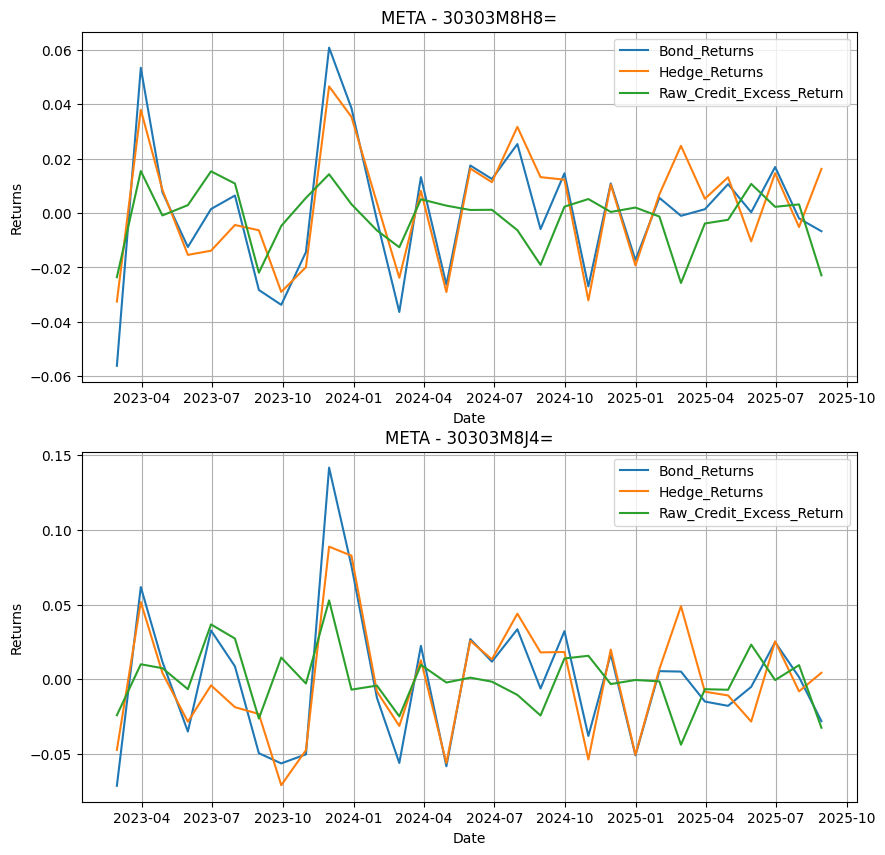

AMZN


,RIC,Data_Points_Count
2,023135BF2=,87
4,023135BM7=,87


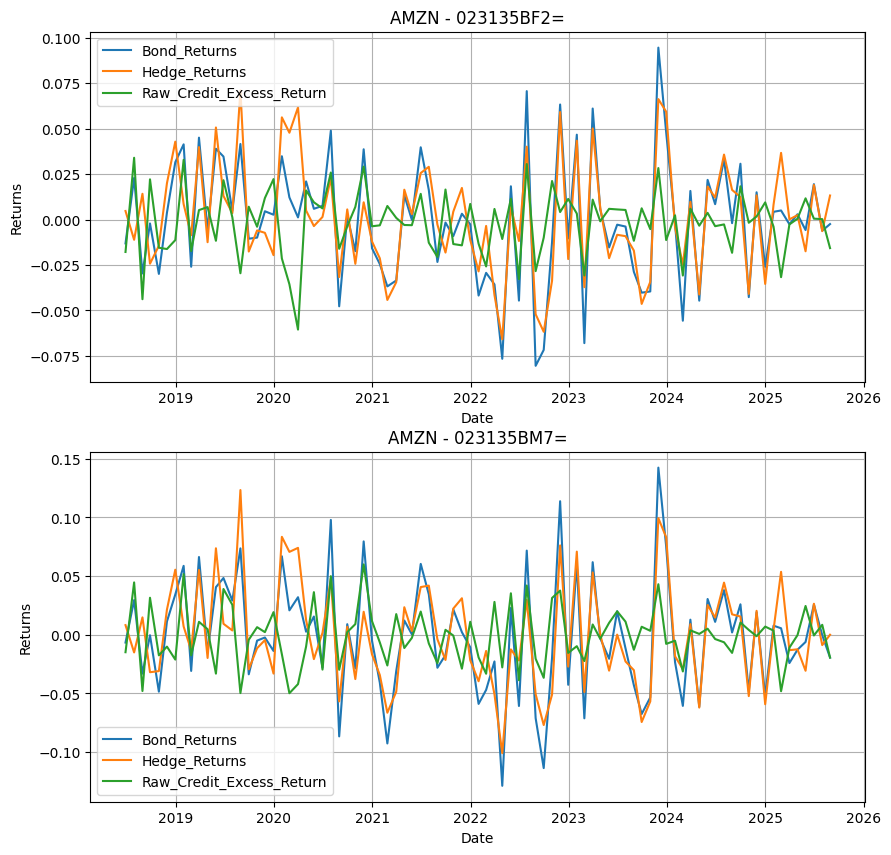

AAPL


,RIC,Data_Points_Count
0,037833AL4=,91
1,037833BA7=,91


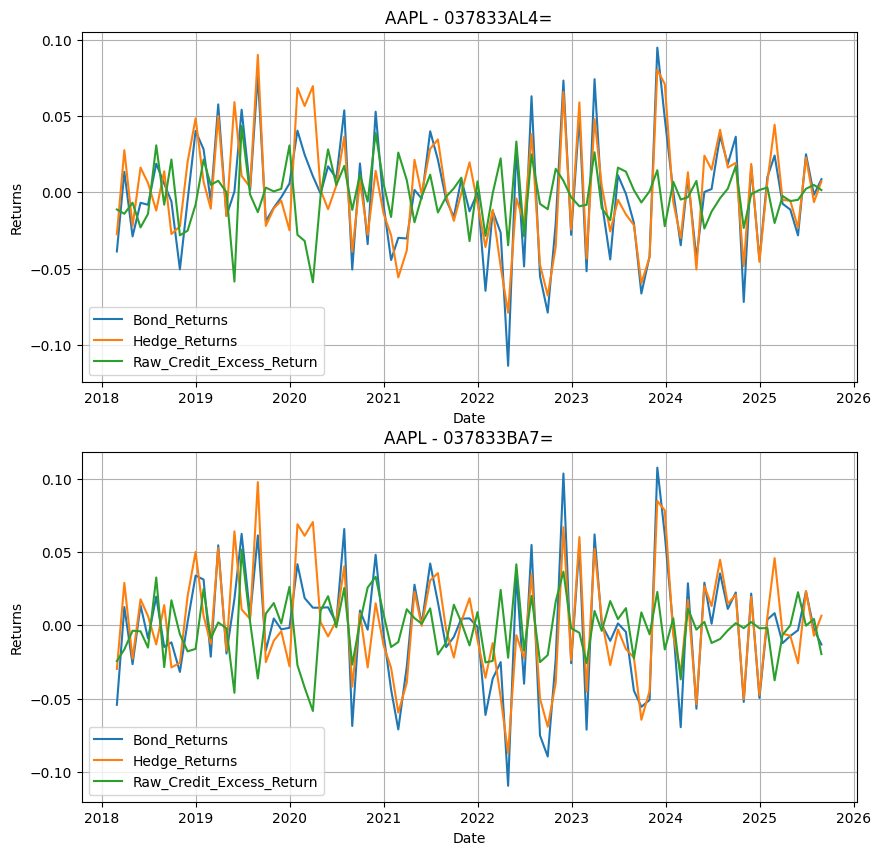

NFLX


,RIC,Data_Points_Count
0,64110LAN6=,67
2,64110LAT3=,67


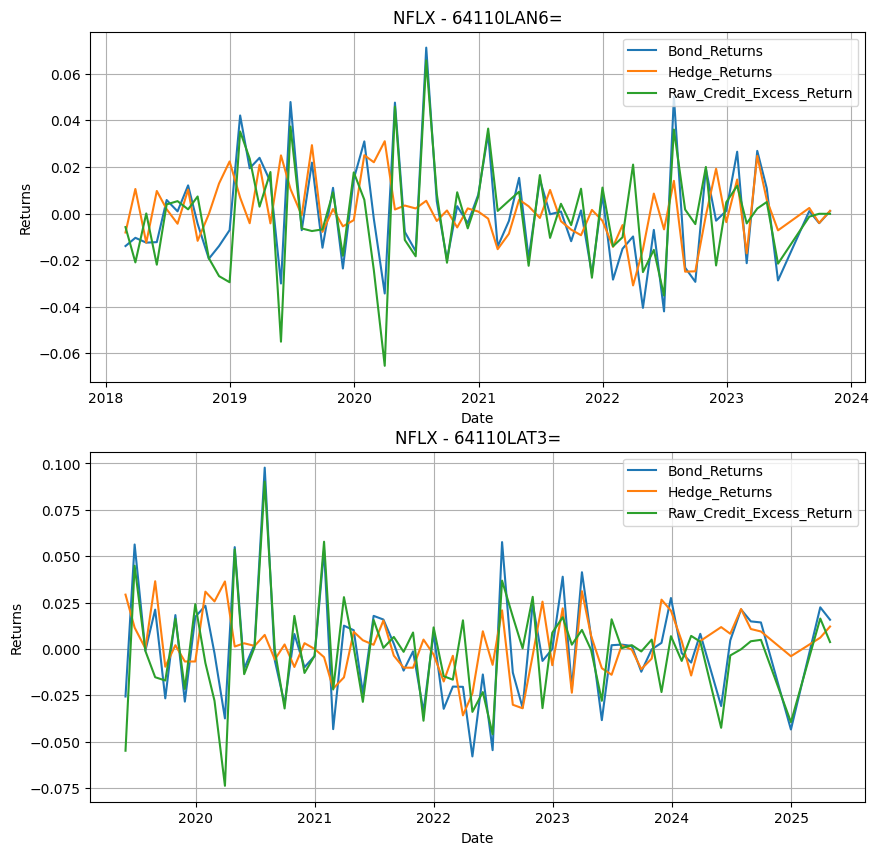

GOOGL


,RIC,Data_Points_Count
0,02079KAC1=,11
1,02079KAL1=,4


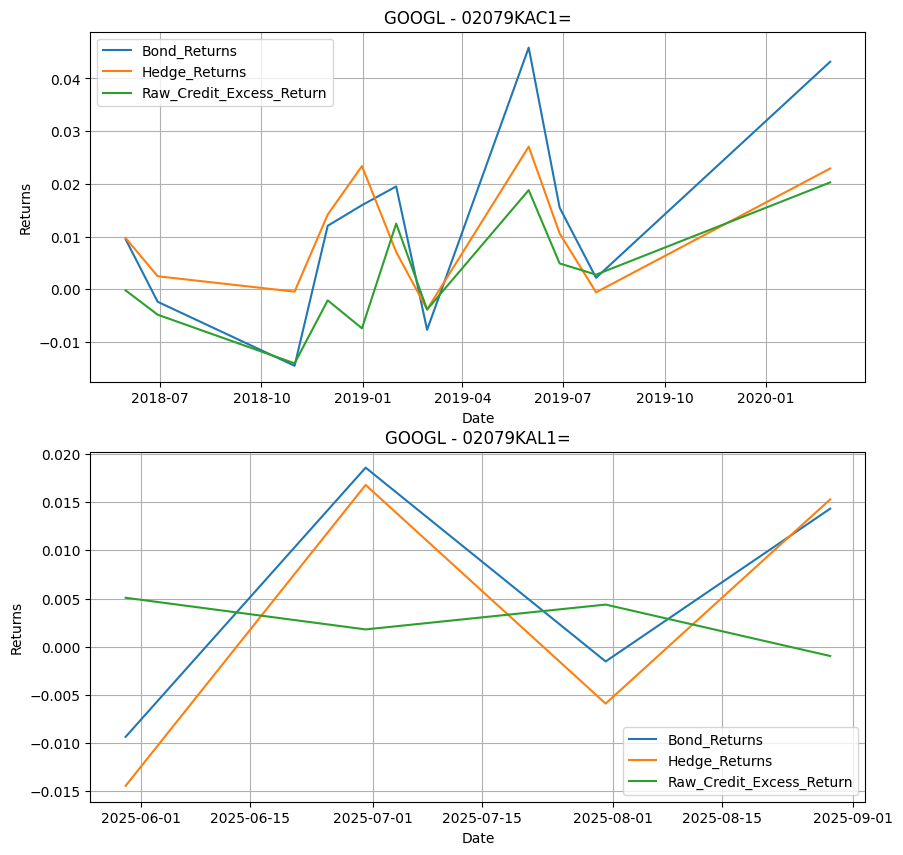

In [249]:
# Plotting FAANG returns
faang = ["META", "AMZN", "AAPL", "NFLX", "GOOGL"]

for ticker in faang:
    ticker_data = yield_book.loc[yield_book['Ticker']==ticker]
    sorted_ric = ticker_data.groupby(['RIC'])['Ticker'].count().reset_index().rename(columns={'Ticker':'Data_Points_Count'}).sort_values(by=['Data_Points_Count'], ascending=False)
    most_data_2 = sorted_ric['RIC'].iloc[:2].tolist()
    print(ticker)
    display(sorted_ric.iloc[:2])
    fig, ax = plt.subplots(2, 1, figsize = (10,10))
    for i, ric in enumerate(most_data_2):
        ric_data = ticker_data.loc[ticker_data['RIC']==ric]

        # ax[i].plot(ric_data['PricingDate'], ric_data['Price'])
        ax[i].plot(ric_data['PricingDate'], ric_data['Returns'])
        ax[i].plot(ric_data['PricingDate'], ric_data['Hedge_Returns'])
        ax[i].plot(ric_data['PricingDate'], ric_data['Raw_Credit_Excess_Return'])

        ax[i].set_xlabel('Date')
        ax[i].set_ylabel('Returns')
        ax[i].set_title(f"{ticker} - {ric}")
        ax[i].legend(['Bond_Returns', 'Hedge_Returns', 'Raw_Credit_Excess_Return'])
        ax[i].grid(True)

    plt.show()


META


,RIC,Data_Points_Count
1,30303M8H8=,31
2,30303M8J4=,31


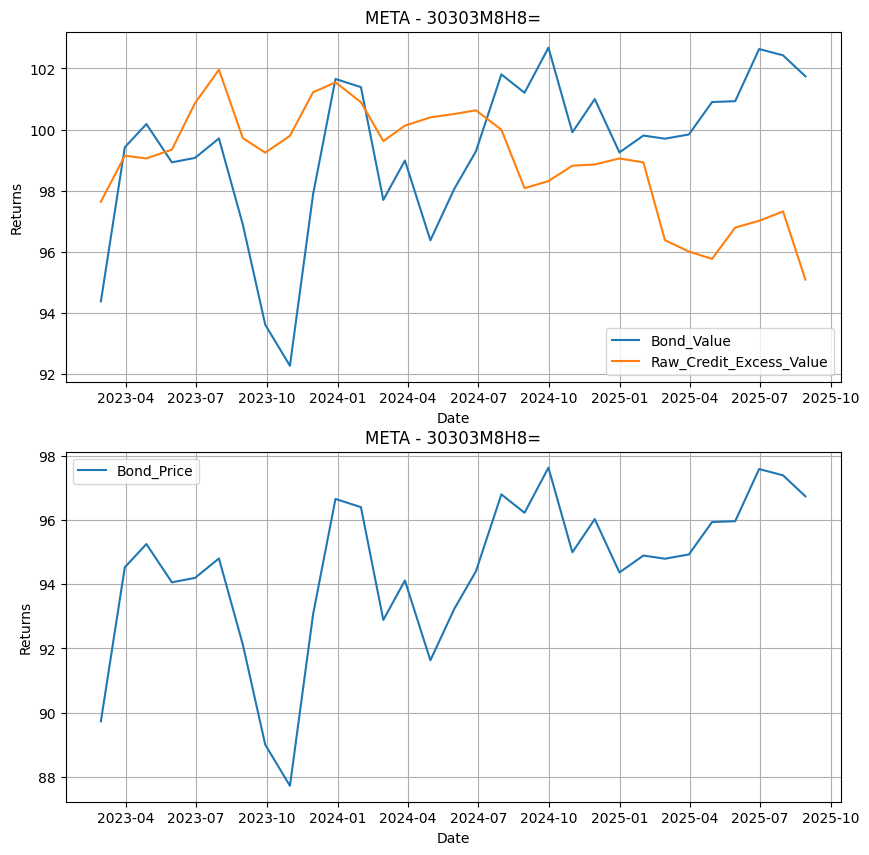

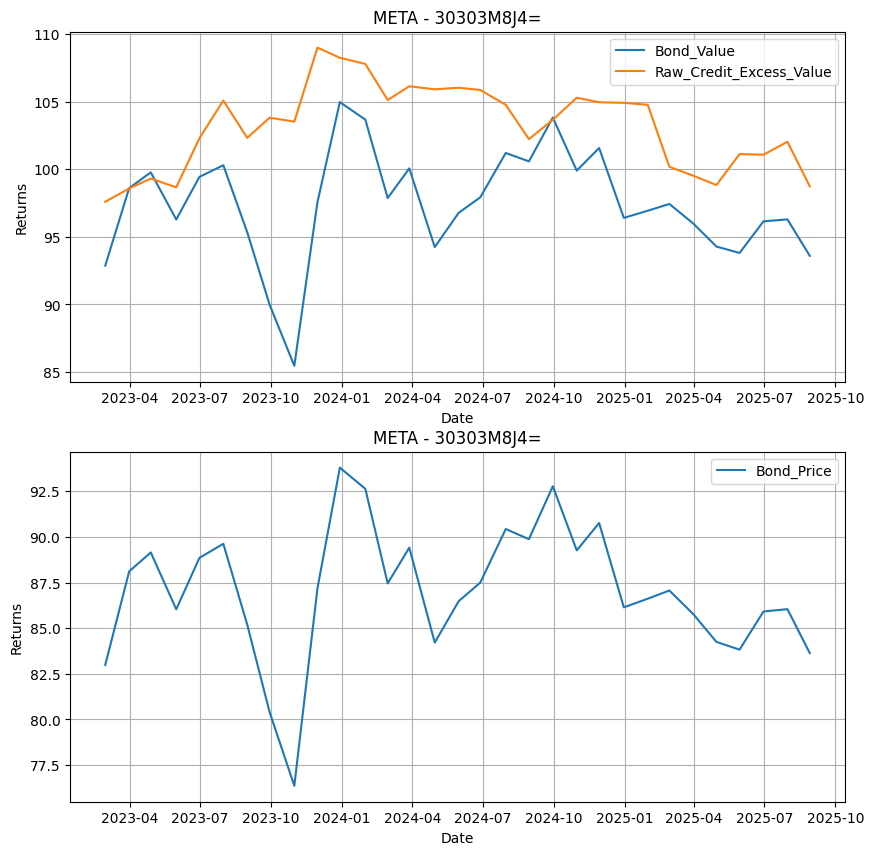

AMZN


,RIC,Data_Points_Count
2,023135BF2=,87
4,023135BM7=,87


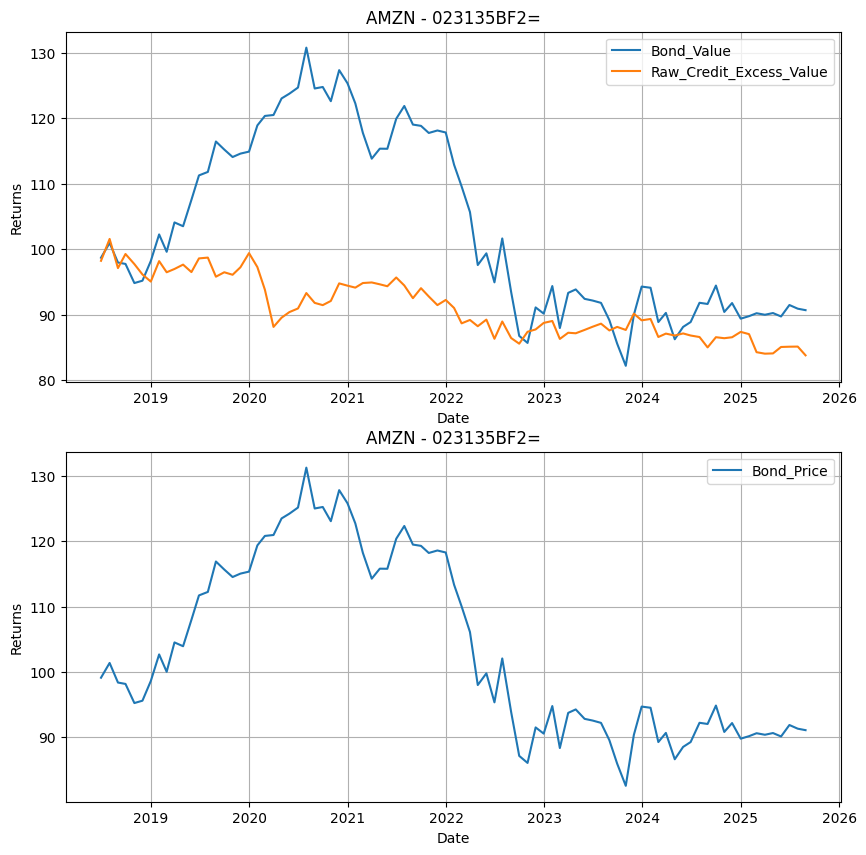

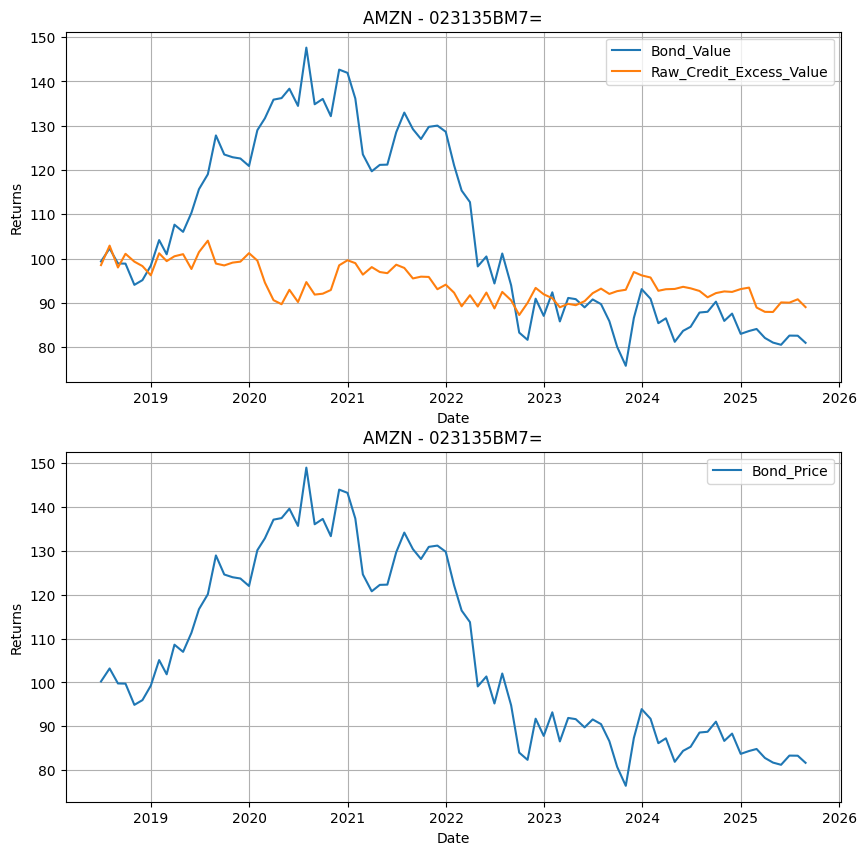

AAPL


,RIC,Data_Points_Count
0,037833AL4=,91
1,037833BA7=,91


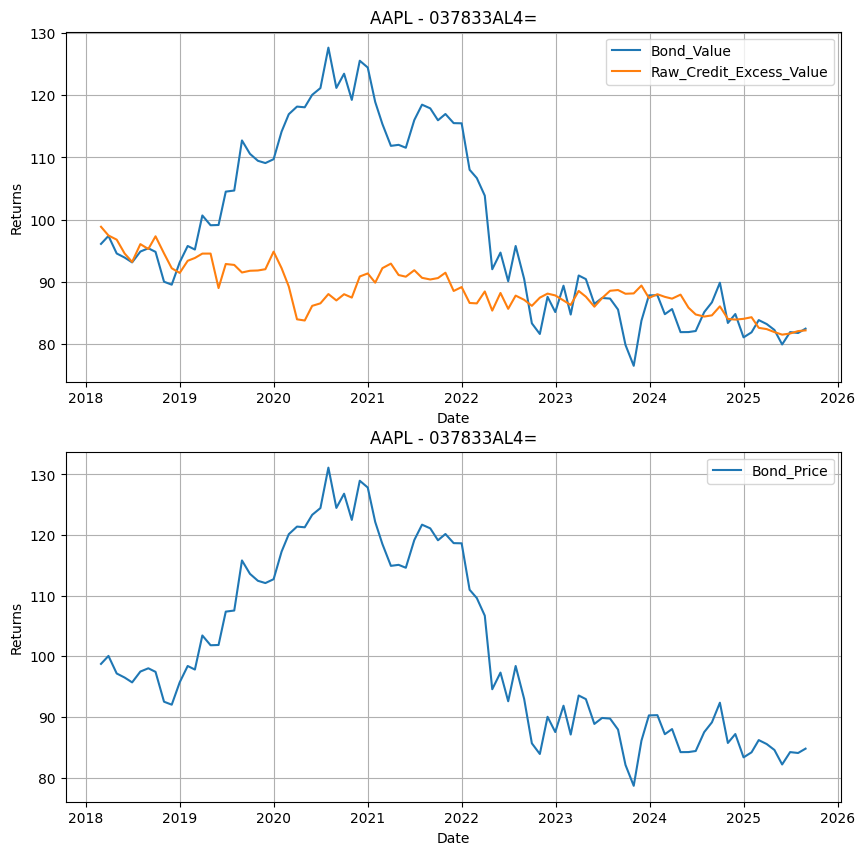

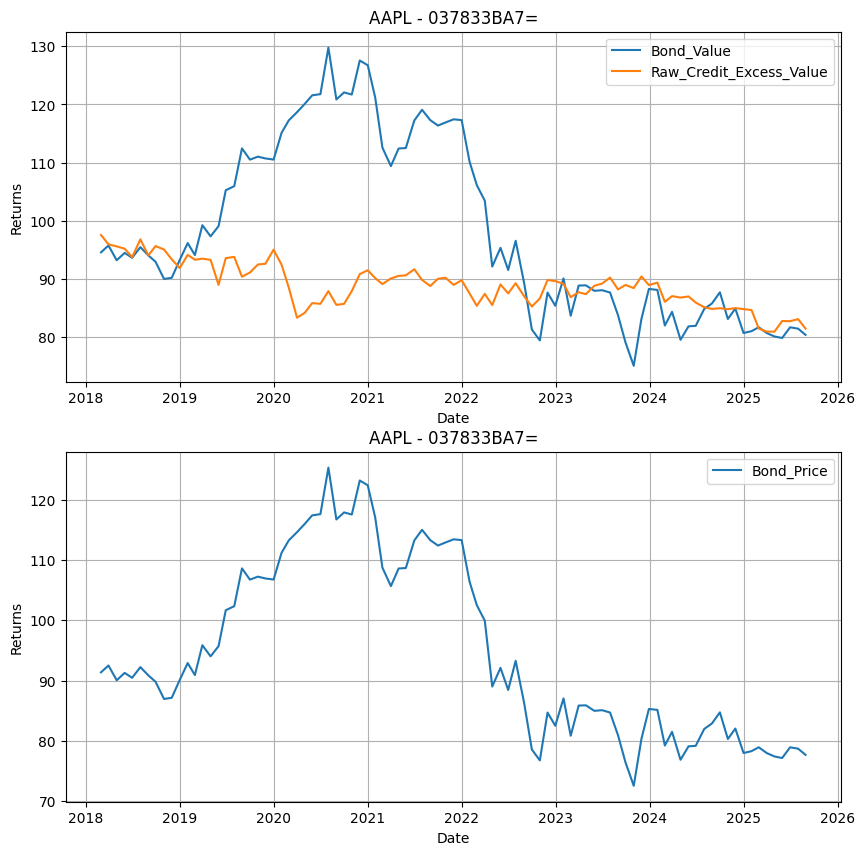

NFLX


,RIC,Data_Points_Count
0,64110LAN6=,67
2,64110LAT3=,67


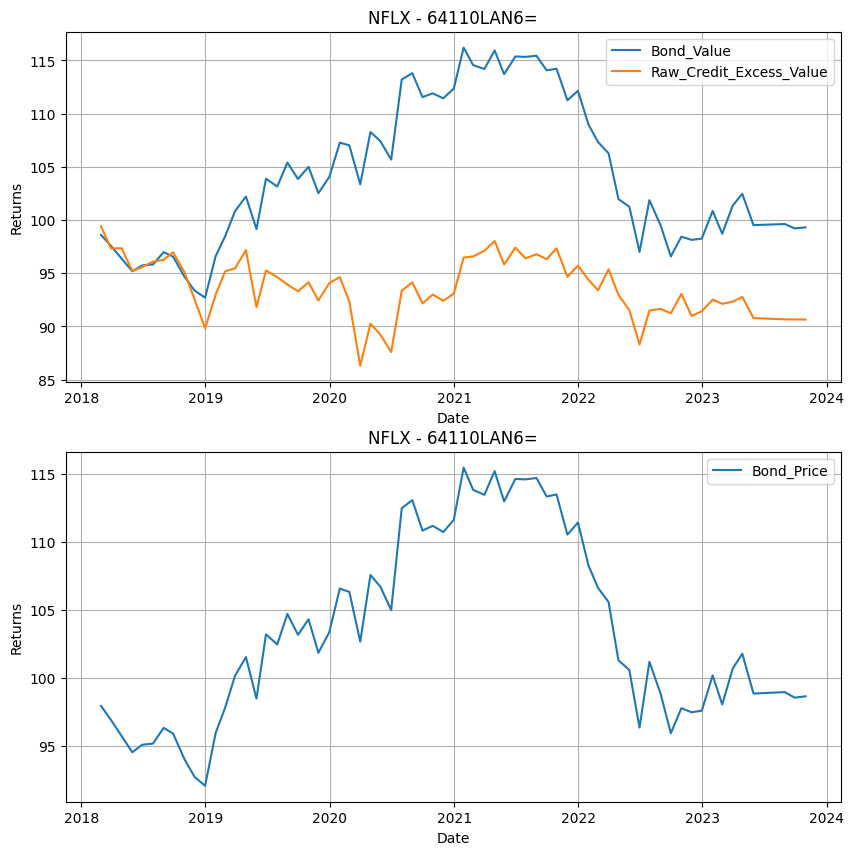

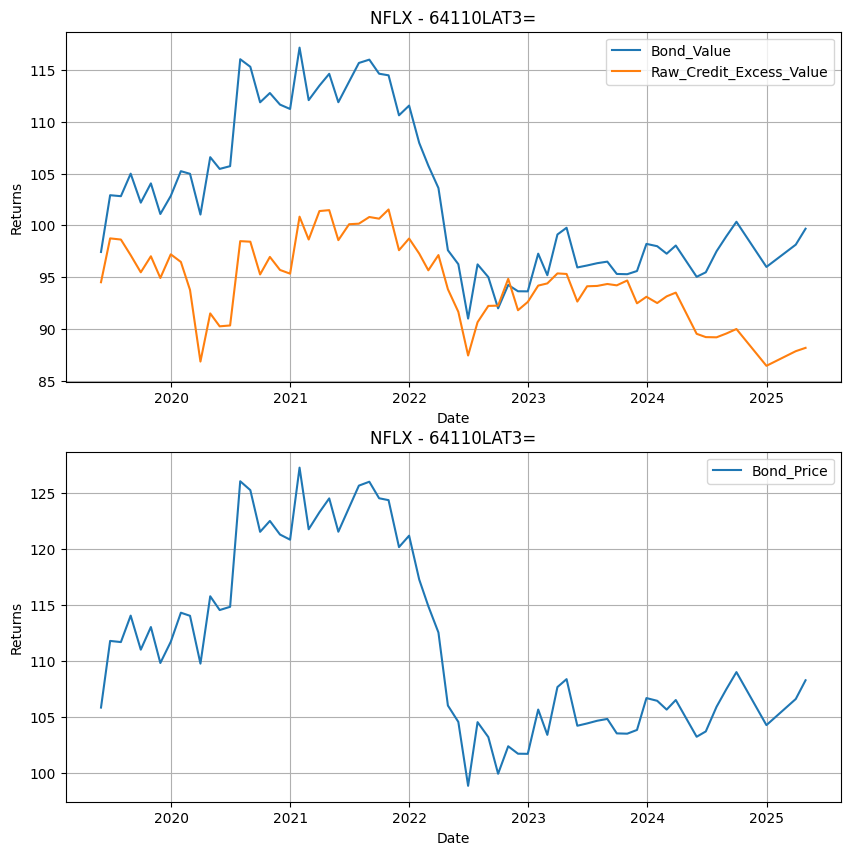

GOOGL


,RIC,Data_Points_Count
0,02079KAC1=,11
1,02079KAL1=,4


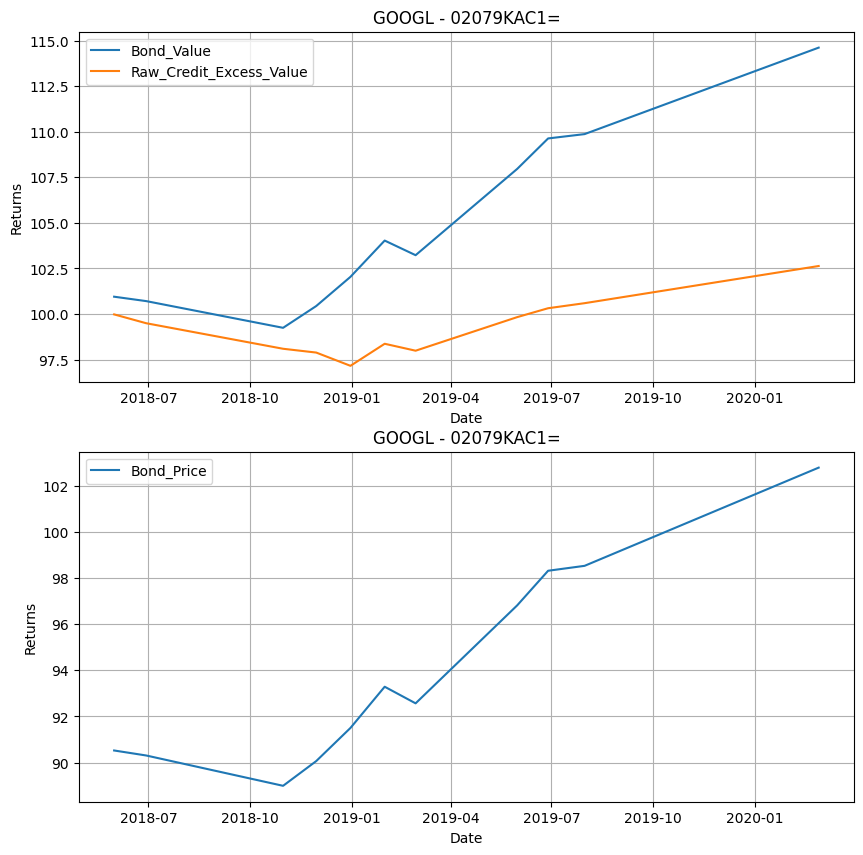

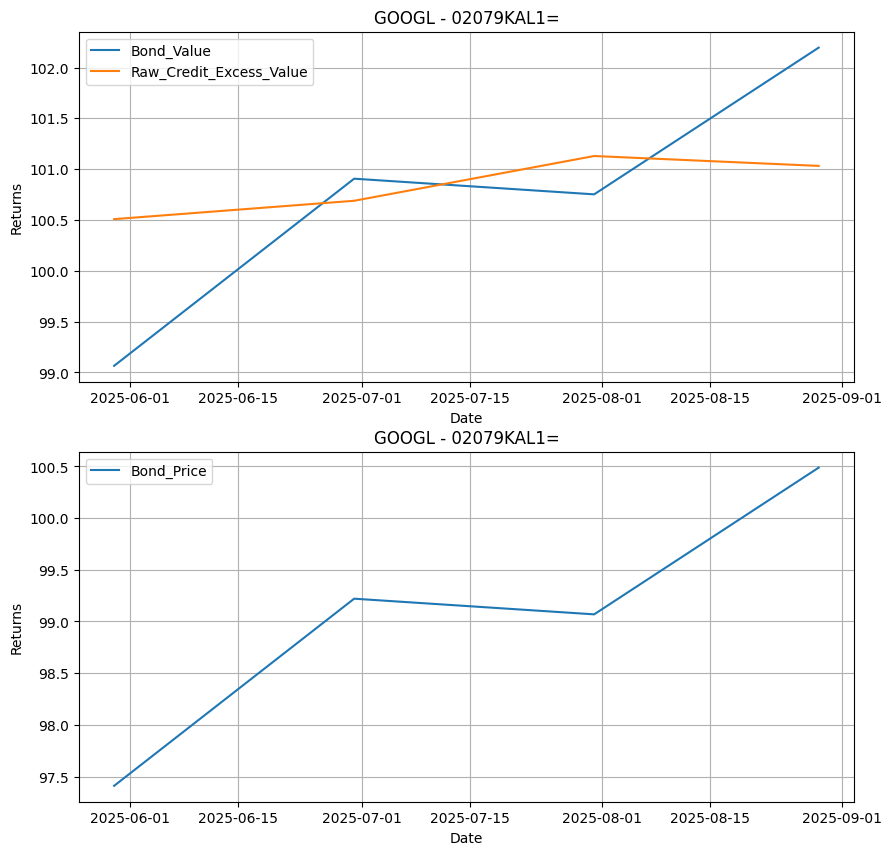

In [250]:
# Plotting FAANG returns
faang = ["META", "AMZN", "AAPL", "NFLX", "GOOGL"]

for ticker in faang:
    ticker_data = yield_book.loc[yield_book['Ticker']==ticker]
    sorted_ric = ticker_data.groupby(['RIC'])['Ticker'].count().reset_index().rename(columns={'Ticker':'Data_Points_Count'}).sort_values(by=['Data_Points_Count'], ascending=False)
    most_data_2 = sorted_ric['RIC'].iloc[:2].tolist()
    print(ticker)
    display(sorted_ric.iloc[:2])
    for i, ric in enumerate(most_data_2):
        fig, ax = plt.subplots(2, 1, figsize = (10,10))
        ric_data = ticker_data.loc[ticker_data['RIC']==ric]

        ax[0].plot(ric_data['PricingDate'], 100*(1+ric_data['Returns']).cumprod())
        ax[0].plot(ric_data['PricingDate'], 100*(1+ric_data['Raw_Credit_Excess_Return']).cumprod())

        ax[0].set_xlabel('Date')
        ax[0].set_ylabel('Returns')
        ax[0].set_title(f"{ticker} - {ric}")
        ax[0].legend(['Bond_Value', 'Raw_Credit_Excess_Value'])
        ax[0].grid(True)

        ax[1].plot(ric_data['PricingDate'], ric_data['FullPrice'])
        ax[1].set_xlabel('Date')
        ax[1].set_ylabel('Returns')
        ax[1].set_title(f"{ticker} - {ric}")
        ax[1].legend(['Bond_Price'])
        ax[1].grid(True)

    plt.show()


In [26]:
import ipca

In [28]:
display(yield_book.columns)

Index(['CUSIP', 'PricingDate', 'Ticker', 'Description', 'SecurityType',
       'MaturityDate', 'Price', 'FullPrice', 'AccruedInterest', 'AccruedDays',
       'SettlementDate', 'Yield', 'YieldToWorst', 'YieldToWorstCall',
       'CurrentYield', 'EffectiveYield', 'AnnualizedYield',
       'SemiAnnualizedYield', 'CDYield', 'OAS', 'ZSpread', 'ZISpread',
       'ZNSpread', 'AssetSwapSpread', 'GrossSpread', 'SpreadToActCurve',
       'SpreadToTsyCurve', 'SpreadToBenchmark', 'SpreadToSwapCurve',
       'SpreadToRFRSwapCurve', 'SpreadToWorstCall', 'YieldCurveMargin',
       'Duration', 'EffectiveDuration', 'MacaulayDuration', 'SpreadDuration',
       'YieldCurveDuration', 'SpreadDurationTreasury', 'DurationToWorstCase',
       'FundedEffectiveDuration', 'EffectiveDurationPriceUp',
       'EffectiveDurationPriceDown', 'Convexity', 'EffectiveConvexity',
       'MacaulayConvexity', 'SpreadConvexity', 'ConvexityCost',
       'ConvexityEffect', 'FundedEffectiveConvexity', 'DV01', 'EffectiveDV01',
 

In [55]:
display(yield_book.columns)

Index(['CUSIP', 'PricingDate', 'Ticker', 'Description', 'SecurityType',
       'MaturityDate', 'Price', 'FullPrice', 'AccruedInterest', 'AccruedDays',
       'SettlementDate', 'Yield', 'YieldToWorst', 'YieldToWorstCall',
       'CurrentYield', 'EffectiveYield', 'AnnualizedYield',
       'SemiAnnualizedYield', 'CDYield', 'OAS', 'ZSpread', 'ZISpread',
       'ZNSpread', 'AssetSwapSpread', 'GrossSpread', 'SpreadToActCurve',
       'SpreadToTsyCurve', 'SpreadToBenchmark', 'SpreadToSwapCurve',
       'SpreadToRFRSwapCurve', 'SpreadToWorstCall', 'YieldCurveMargin',
       'Duration', 'EffectiveDuration', 'MacaulayDuration', 'SpreadDuration',
       'YieldCurveDuration', 'SpreadDurationTreasury', 'DurationToWorstCase',
       'FundedEffectiveDuration', 'EffectiveDurationPriceUp',
       'EffectiveDurationPriceDown', 'Convexity', 'EffectiveConvexity',
       'MacaulayConvexity', 'SpreadConvexity', 'ConvexityCost',
       'ConvexityEffect', 'FundedEffectiveConvexity', 'DV01', 'EffectiveDV01',
 

In [ ]:
# 5 main - 'Duration', Spread - 'OAS', Bond Volatility -'DtS'?, 'Spread-to-D2D'?, 'Constant'
# Others Available in YieldBook - 'Bond Age', 'Coupon'
# Others Available but not in YieldBook - 'Face Value at Issue', 'Book to price',




In [43]:
characteristics = pd.read_parquet(r'../data/datascope_characteristic_eod.parquet')

In [45]:
display(characteristics.columns)

Index(['RIC', 'Trade Date', 'Asset ID', 'Asset Status',
       'Asset Status Description', 'Asset SubType',
       'Asset SubType Description', 'Asset Type', 'Asset Type Description',
       'Country of Incorporation', 'Country of Incorporation Description',
       'Currency Code', 'Currency Code Description',
       'ESMA Standard Market Size Currency Code', 'Exchange Code',
       'Exchange Description', 'Instrument ID', 'Instrument ID Type',
       'Issue PermID', 'Issuer Name', 'Issuer OrgID', 'Issuer PermID',
       'Quote ID', 'Reference Company', 'Security Description', 'Ticker'],
      dtype='object')

In [48]:
resampled_from_tick = pd.read_parquet(r'../data/datascope_eod_resampled_from_tick_complete.parquet')

In [50]:
display(resampled_from_tick)

,Date-Time,#RIC,Domain,GMT Offset,Ex/Cntrb.ID,Bid Price,Ask Price,Qualifiers,Exch Time,Bid Yld,...,Interpolated CDS Spread,Closest-to-Maturity CDS Basis,1M Basis Asset Swap Spread,3M Basis Asset Swap Spread,6M Basis Asset Swap Spread,Mid Yield,Option Adjusted Spread,Net Change,Old Value,New Value
0,2018-10-31 00:00:00+00:00,001055AY8=,Market Price,0,None,97.4510,98.2240,None,None,NaN,...,139.2,-28.5046,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-11-01 00:00:00+00:00,001055AY8=,Market Price,0,None,97.8360,98.6130,None,None,NaN,...,139.2,-27.0347,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2018-11-02 00:00:00+00:00,001055AY8=,Market Price,0,None,97.4390,98.2120,None,None,NaN,...,139.2,-22.1841,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2018-11-03 00:00:00+00:00,001055AY8=,Market Price,0,None,NaN,NaN,None,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,840.0
4,2018-11-05 00:00:00+00:00,001055AY8=,Market Price,0,None,97.7960,98.5720,None,None,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1922152,2025-09-25 00:00:00+00:00,US046686063=,Market Price,0,None,103.7125,104.0217,B[ACT_TP_1]; A[SC_ACT_TP1],21:08:02.000000000,5.1297,...,NaN,NaN,NaN,NaN,NaN,5.1147,NaN,NaN,NaN,NaN
1922153,2025-09-26 00:00:00+00:00,US046686063=,Market Price,0,None,103.9054,104.2152,B[ACT_TP_1]; A[SC_ACT_TP1],21:18:04.000000000,5.1108,...,NaN,NaN,NaN,NaN,NaN,5.0958,NaN,NaN,NaN,NaN
1922154,2025-09-29 00:00:00+00:00,US046686063=,Market Price,0,None,104.6399,104.9525,B[ACT_TP_1]; A[SC_ACT_TP1],21:08:02.000000000,5.0398,...,NaN,NaN,NaN,NaN,NaN,5.0248,NaN,NaN,NaN,NaN
1922155,2025-09-30 00:00:00+00:00,US046686063=,Market Price,0,None,104.1326,104.4432,B[ACT_TP_1]; A[SC_ACT_TP1],21:08:02.000000000,5.0887,...,NaN,NaN,NaN,NaN,NaN,5.0737,NaN,NaN,NaN,NaN


In [56]:
display(resampled_from_tick.columns)

Index(['Date-Time', '#RIC', 'Domain', 'GMT Offset', 'Ex/Cntrb.ID', 'Bid Price',
       'Ask Price', 'Qualifiers', 'Exch Time', 'Bid Yld', 'Ask Yld',
       'ISMA Bid Yld', 'ISMA Ask Yld', 'Duration', 'Mod Durtn', 'BPV',
       'Convexity', 'Bench Spd', 'Swp Spd', 'Asst Swp Spd', 'Swap Point',
       'Premium', 'Date', 'Open', 'High', 'Low', 'Open Yld', 'High Yld',
       'Low Yld', 'Mid Price', 'Option Adjusted Spread Bid', 'Z Spread',
       'Conversion Premium', 'Percentage Daily Return',
       'Interpolated CDS Basis', 'Interpolated CDS Spread',
       'Closest-to-Maturity CDS Basis', '1M Basis Asset Swap Spread',
       '3M Basis Asset Swap Spread', '6M Basis Asset Swap Spread', 'Mid Yield',
       'Option Adjusted Spread', 'Net Change', 'Old Value', 'New Value'],
      dtype='object')

In [51]:
fin_statement = pd.read_parquet(r'../data/fmp_hist_financial_statements.parquet')

In [52]:
display(fin_statement)

,date,symbol,reportedCurrency,cik,filingDate,acceptedDate,fiscalYear,period,cashAndCashEquivalents,shortTermInvestments,...,netIncomePerEBT,ebtPerEbit,priceToFairValue,debtToMarketCap,effectiveTaxRate,enterpriseValueMultiple,dividendPerShare,processed_at_financial_ratios,asof_date_financial_ratios,RIC
127,2017-09-30,AAPL,USD,320193,2017-11-03,2017-11-03 08:01:37,2017,FY,2.028900e+10,5.389200e+10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,None,037833EL0=
128,2016-12-31,AAPL,USD,320193,2017-02-01,2017-02-01 16:33:29,2017,Q1,1.637100e+10,4.408100e+10,...,0.739909,1.035147,4.636278,0.142635,0.260091,24.735479,0.147679,2025-10-23 02:35:26.233572,2025-10-23,037833EL0=
129,2017-04-01,AAPL,USD,320193,2017-05-03,2017-05-03 16:32:23,2017,Q2,1.515700e+10,5.194400e+10,...,0.751090,1.041640,5.599869,0.131215,0.248910,47.543979,0.143710,2025-10-23 02:35:26.233572,2025-10-23,037833EL0=
130,2017-07-01,AAPL,USD,320193,2017-08-02,2017-08-02 16:31:28,2017,Q3,1.857100e+10,5.818800e+10,...,0.770870,1.050149,5.650749,0.144780,0.229130,58.754100,0.161932,2025-10-23 02:35:26.233572,2025-10-23,037833EL0=
131,2017-09-30,AAPL,USD,320193,2017-11-03,2017-11-03 08:01:37,2017,Q4,2.028900e+10,5.389200e+10,...,0.769850,1.060747,5.920534,0.145761,0.230150,52.090048,0.158755,2025-10-23 02:35:26.233572,2025-10-23,037833EL0=
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
40401,2024-06-30,ZTS,USD,1555280.0,2024-08-06,2024-08-06 12:41:47,2024,Q2,1.573000e+09,0.000000e+00,...,0.800000,0.860927,15.829680,0.083488,0.200000,86.372361,0.432492,2025-10-23 02:44:58.243598,2025-10-23,98978VAH6=
40402,2024-09-30,ZTS,USD,1555280.0,2024-11-04,2024-11-04 13:52:13,2024,Q3,1.710000e+09,0.000000e+00,...,0.780320,0.950000,16.906305,0.074293,0.208238,88.572540,0.434975,2025-10-23 02:44:58.243598,2025-10-23,98978VAH6=
40403,2024-12-31,ZTS,USD,1555280.0,2025-02-13,2025-02-13 14:51:25,2024,Q4,1.985000e+09,0.000000e+00,...,0.793716,0.956863,15.387833,0.089510,0.206284,85.794693,0.430633,2025-10-23 02:44:58.243598,2025-10-23,98978VAH6=
40404,2025-03-31,ZTS,USD,1555280.0,2025-05-06,2025-05-06 13:29:54,2025,Q1,1.721000e+09,0.000000e+00,...,0.779012,0.957447,15.831867,0.089243,0.220988,79.682530,0.500447,2025-10-23 02:44:58.243598,2025-10-23,98978VAH6=


In [54]:
display(fin_statement.columns.tolist())

['date',
 'symbol',
 'reportedCurrency',
 'cik',
 'filingDate',
 'acceptedDate',
 'fiscalYear',
 'period',
 'cashAndCashEquivalents',
 'shortTermInvestments',
 'cashAndShortTermInvestments',
 'netReceivables',
 'accountsReceivables',
 'otherReceivables',
 'inventory',
 'prepaids',
 'otherCurrentAssets',
 'totalCurrentAssets',
 'propertyPlantEquipmentNet',
 'goodwill',
 'intangibleAssets',
 'goodwillAndIntangibleAssets',
 'longTermInvestments',
 'taxAssets',
 'otherNonCurrentAssets',
 'totalNonCurrentAssets',
 'otherAssets',
 'totalAssets',
 'totalPayables',
 'accountPayables',
 'otherPayables',
 'accruedExpenses',
 'shortTermDebt',
 'capitalLeaseObligationsCurrent',
 'taxPayables',
 'deferredRevenue',
 'otherCurrentLiabilities',
 'totalCurrentLiabilities',
 'longTermDebt',
 'capitalLeaseObligationsNonCurrent',
 'deferredRevenueNonCurrent',
 'deferredTaxLiabilitiesNonCurrent',
 'otherNonCurrentLiabilities',
 'totalNonCurrentLiabilities',
 'otherLiabilities',
 'capitalLeaseObligations',


In [ ]:
performance = pd.read_parquet(r'../data/fmp_market_performance.parquet')

In [ ]:
display(performance)